# 03 — Évaluer, comparer et prédire

Ce notebook compare la baseline et la variante CLAHE sur **exactement les mêmes observations**. Il produit :

- accuracy, top-3 accuracy, F1 weighted et F1 macro ;
- rapport et matrice de confusion normalisée ;
- comparaison par classe ;
- inspection visuelle des erreurs les plus confiantes ;
- prédictions du test si `data/raw_x_test.csv` est disponible.

Le choix final doit privilégier le F1 weighted, tout en surveillant le F1 macro afin de ne pas sacrifier
les petites classes.


In [1]:
from pathlib import Path
import json
import os
import random

import certifi
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Python installé depuis python.org sur macOS ne référence pas toujours le trousseau
# système. On fournit à urllib/Keras un bundle CA explicite sans désactiver SSL.
os.environ["SSL_CERT_FILE"] = certifi.where()
os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()

def find_project_root() -> Path:
    """Permet d'exécuter le notebook depuis sa racine ou son propre dossier."""
    candidates = [Path.cwd(), *Path.cwd().parents]
    for candidate in candidates:
        if (candidate / "data" / "raw_x.csv").exists() and (candidate / "images").exists():
            return candidate
    raise FileNotFoundError("Racine du projet introuvable (data/raw_x.csv et images/ attendus).")

ROOT = find_project_root()
DATA_DIR = ROOT / "data"
IMAGE_DIR = ROOT / "images" / "image_train"
ARTIFACTS_DIR = ROOT / "artifacts" / "image_classification"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("KERAS_HOME", str(ARTIFACTS_DIR / ".keras"))

print("Racine :", ROOT)
print("Artefacts :", ARTIFACTS_DIR)
print("Certificats SSL :", os.environ["SSL_CERT_FILE"])


Racine : /Users/wolfidy7/projects/sep25_alt2_iia_rakuten_2
Artefacts : /Users/wolfidy7/projects/sep25_alt2_iia_rakuten_2/artifacts/image_classification
Certificats SSL : /Users/wolfidy7/projects/sep25_alt2_iia_rakuten_2/.conda/rakuten-metal/lib/python3.10/site-packages/certifi/cacert.pem


In [2]:
import tensorflow as tf

tf.keras.utils.set_random_seed(SEED)

TARGET_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

with open(ARTIFACTS_DIR / "class_mapping.json", encoding="utf-8") as handle:
    class_mapping = json.load(handle)

index_to_code = [int(value) for value in class_mapping["index_to_code"]]
code_to_index = {code: index for index, code in enumerate(index_to_code)}
NUM_CLASSES = len(index_to_code)

category_names = {
    10: "Livres occasion",
    2280: "Journaux et revues occasion",
    2403: "Livres, BD et magazines",
    2522: "Fournitures papeterie et accessoires bureau",
    2705: "Livres neufs",
    40: "Jeux vidéos, CDs, équipements, câbles, neufs",
    50: "Accessoires gaming",
    60: "Consoles de jeu",
    2462: "Jeux vidéos occasion",
    2905: "Jeux vidéos pour PC",
    1140: "Figurines, objets pop culture",
    1160: "Cartes de jeux",
    1180: "Figurines et jeux de rôles",
    1280: "Jouets enfants",
    1281: "Jeux société enfants",
    1300: "Modélisme",
    1302: "Jeux de plein air, habits",
    1560: "Mobilier général",
    2582: "Mobilier de jardin",
    1320: "Puériculture, accessoires bébé",
    2220: "Animalerie",
    2583: "Piscine et accessoires",
    2585: "Outillage de jardin, équipements extérieurs",
    1920: "Linge de maison, oreillers, coussins",
    2060: "Décoration",
    1301: "Chaussettes bébés, petites photos",
    1940: "Confiserie",
}
missing_category_names = sorted(set(index_to_code) - set(category_names))
if missing_category_names:
    raise ValueError(f"Libellés manquants pour les catégories : {missing_category_names}")
readable_class_labels = [f"{code} — {category_names[code]}" for code in index_to_code]

manifest = pd.read_csv(ARTIFACTS_DIR / "image_manifest.csv")
manifest["class_index"] = manifest["prdtypecode"].map(code_to_index)
assert manifest["class_index"].notna().all()

def decode_resize(path, label, weight):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize_with_pad(image, *TARGET_SIZE, antialias=True)
    image = tf.cast(image, tf.float32)  # EfficientNet attend des pixels dans [0, 255].
    return image, tf.cast(label, tf.int32), tf.cast(weight, tf.float32)

def make_dataset(frame, training=False, transform=None, weighted=False):
    paths = frame["image_path"].astype(str).to_numpy()
    labels = frame["class_index"].astype("int32").to_numpy()
    weights = frame["sample_weight"].astype("float32").to_numpy()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels, weights))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(decode_resize, num_parallel_calls=AUTOTUNE)
    if transform is not None:
        ds = ds.map(transform, num_parallel_calls=AUTOTUNE)
    if not weighted:
        ds = ds.map(lambda x, y, w: (x, y), num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_df = manifest.query("split == 'train'").copy()
val_df = manifest.query("split == 'validation'").copy()
print(f"Train={len(train_df):,} | Validation={len(val_df):,} | Classes={NUM_CLASSES}")


Train=65,900 | Validation=16,475 | Classes=27


In [3]:
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    f1_score, top_k_accuracy_score,
)

def clahe_numpy(image):
    image_uint8 = np.clip(image, 0, 255).astype(np.uint8)
    lab = cv2.cvtColor(image_uint8, cv2.COLOR_RGB2LAB)
    lightness, channel_a, channel_b = cv2.split(lab)
    if float(lightness.std()) >= 40.0:
        return image_uint8.astype(np.float32)
    enhanced = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lightness)
    return cv2.cvtColor(
        cv2.merge((enhanced, channel_a, channel_b)), cv2.COLOR_LAB2RGB
    ).astype(np.float32)

def apply_clahe_tf(image, label, weight):
    image = tf.numpy_function(clahe_numpy, [image], Tout=tf.float32)
    image.set_shape((*TARGET_SIZE, 3))
    return image, label, weight


## 1. Charger les modèles et obtenir les probabilités


In [4]:
from tensorflow import keras
from tensorflow.keras import layers

def build_evaluation_model():
    """Reconstruit l'architecture pour charger des poids sauvés par un Keras plus récent."""
    augmentation = keras.Sequential(
        [
            layers.RandomRotation(0.03, fill_mode="reflect", seed=SEED),
            layers.RandomZoom(0.10, fill_mode="reflect", seed=SEED),
            layers.RandomContrast(0.10, seed=SEED),
        ],
        name="augmentation",
    )
    inputs = keras.Input(shape=(*TARGET_SIZE, 3), name="image")
    x = augmentation(inputs)
    backbone = keras.applications.EfficientNetB0(
        include_top=False, weights=None, input_shape=(*TARGET_SIZE, 3)
    )
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
    x = layers.Dropout(0.30, seed=SEED)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="prdtypecode")(x)
    return keras.Model(inputs, outputs)

def load_evaluation_model(path):
    try:
        return keras.models.load_model(path, compile=False)
    except TypeError as error:
        # Keras 3.15 ajoute ces champs à VarianceScaling ; Keras 3.12 (Metal)
        # ne sait pas les désérialiser. Les poids restent compatibles.
        if "input_axes" not in str(error) and "output_axes" not in str(error):
            raise
        print(f"Chargement rétrocompatible de {path.name}")
        model = build_evaluation_model()
        model.load_weights(path)
        return model

experiments = {
    "baseline": {
        "path": ARTIFACTS_DIR / "efficientnet_baseline" / "best_model.keras",
        "transform": None,
    },
    "clahe": {
        "path": ARTIFACTS_DIR / "efficientnet_clahe" / "best_model.keras",
        "transform": apply_clahe_tf,
    },
}

missing = [str(run["path"]) for run in experiments.values() if not run["path"].exists()]
if missing:
    raise FileNotFoundError("Modèles manquants. Exécuter les notebooks 01 et 02 :\n" + "\n".join(missing))

y_true = val_df["class_index"].to_numpy()
predictions = {}
for name, run in experiments.items():
    ds = make_dataset(val_df, transform=run["transform"], weighted=False)
    model = load_evaluation_model(run["path"])
    probabilities = model.predict(ds, verbose=1)
    predictions[name] = {"probabilities": probabilities, "labels": probabilities.argmax(axis=1)}


2026-10-11 18:58:07.617653: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2026-10-11 18:58:07.617711: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-10-11 18:58:07.617718: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-10-11 18:58:07.617763: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-11 18:58:07.617781: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Chargement rétrocompatible de best_model.keras


2026-10-11 18:58:10.583292: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


515/515 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step
515/515 ━━━━━━━━━━━━━━━━━━━━ 55s 103ms/step


## 2. Tableau de synthèse


In [5]:
metric_rows = []
for name, result in predictions.items():
    y_pred = result["labels"]
    proba = result["probabilities"]
    metric_rows.append({
        "experiment": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "top3_accuracy": top_k_accuracy_score(y_true, proba, k=3, labels=np.arange(NUM_CLASSES)),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted"),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
    })
metrics = pd.DataFrame(metric_rows).set_index("experiment").sort_values("f1_weighted", ascending=False)
display(metrics.style.format("{:.4f}"))
metrics.to_csv(ARTIFACTS_DIR / "model_comparison.csv")
CHAMPION = metrics.index[0]
print("Champion selon F1 weighted :", CHAMPION)


,accuracy,top3_accuracy,f1_weighted,f1_macro
experiment,,,,
baseline,0.6122,0.8207,0.6049,0.5612
clahe,0.6106,0.8245,0.6032,0.5603


Champion selon F1 weighted : baseline


## 3. Analyse par classe et matrice de confusion


In [6]:
reports = {}
for name, result in predictions.items():
    report = classification_report(
        y_true, result["labels"], labels=np.arange(NUM_CLASSES),
        target_names=[str(code) for code in index_to_code], output_dict=True, zero_division=0,
    )
    reports[name] = pd.DataFrame(report).T
    reports[name].insert(
        0, "category_name",
        [category_names.get(int(label), "") if str(label).isdigit() else "" for label in reports[name].index],
    )
    reports[name].to_csv(ARTIFACTS_DIR / f"classification_report_{name}.csv")

per_class = pd.DataFrame({
    "prdtypecode": index_to_code,
    "category_name": [category_names[code] for code in index_to_code],
    "f1_baseline": [reports["baseline"].loc[str(code), "f1-score"] for code in index_to_code],
    "f1_clahe": [reports["clahe"].loc[str(code), "f1-score"] for code in index_to_code],
})
per_class["delta_clahe"] = per_class["f1_clahe"] - per_class["f1_baseline"]
display(per_class.sort_values("delta_clahe"))
per_class.to_csv(ARTIFACTS_DIR / "per_class_comparison.csv", index=False)


,prdtypecode,category_name,f1_baseline,f1_clahe,delta_clahe
22,2582,Mobilier de jardin,0.401316,0.379610,-0.021706
11,1302,"Jeux de plein air, habits",0.408726,0.389340,-0.019386
12,1320,"Puériculture, accessoires bébé",0.473979,0.460931,-0.013048
17,2220,Animalerie,0.437037,0.426357,-0.010680
21,2522,Fournitures papeterie et accessoires bureau,0.625931,0.618954,-0.006978
1,40,"Jeux vidéos, CDs, équipements, câbles, neufs",0.538462,0.532632,-0.005830
13,1560,Mobilier général,0.579495,0.573947,-0.005548
16,2060,Décoration,0.496821,0.491276,-0.005545
18,2280,Journaux et revues occasion,0.738034,0.733954,-0.004080
2,50,Accessoires gaming,0.424028,0.420315,-0.003713


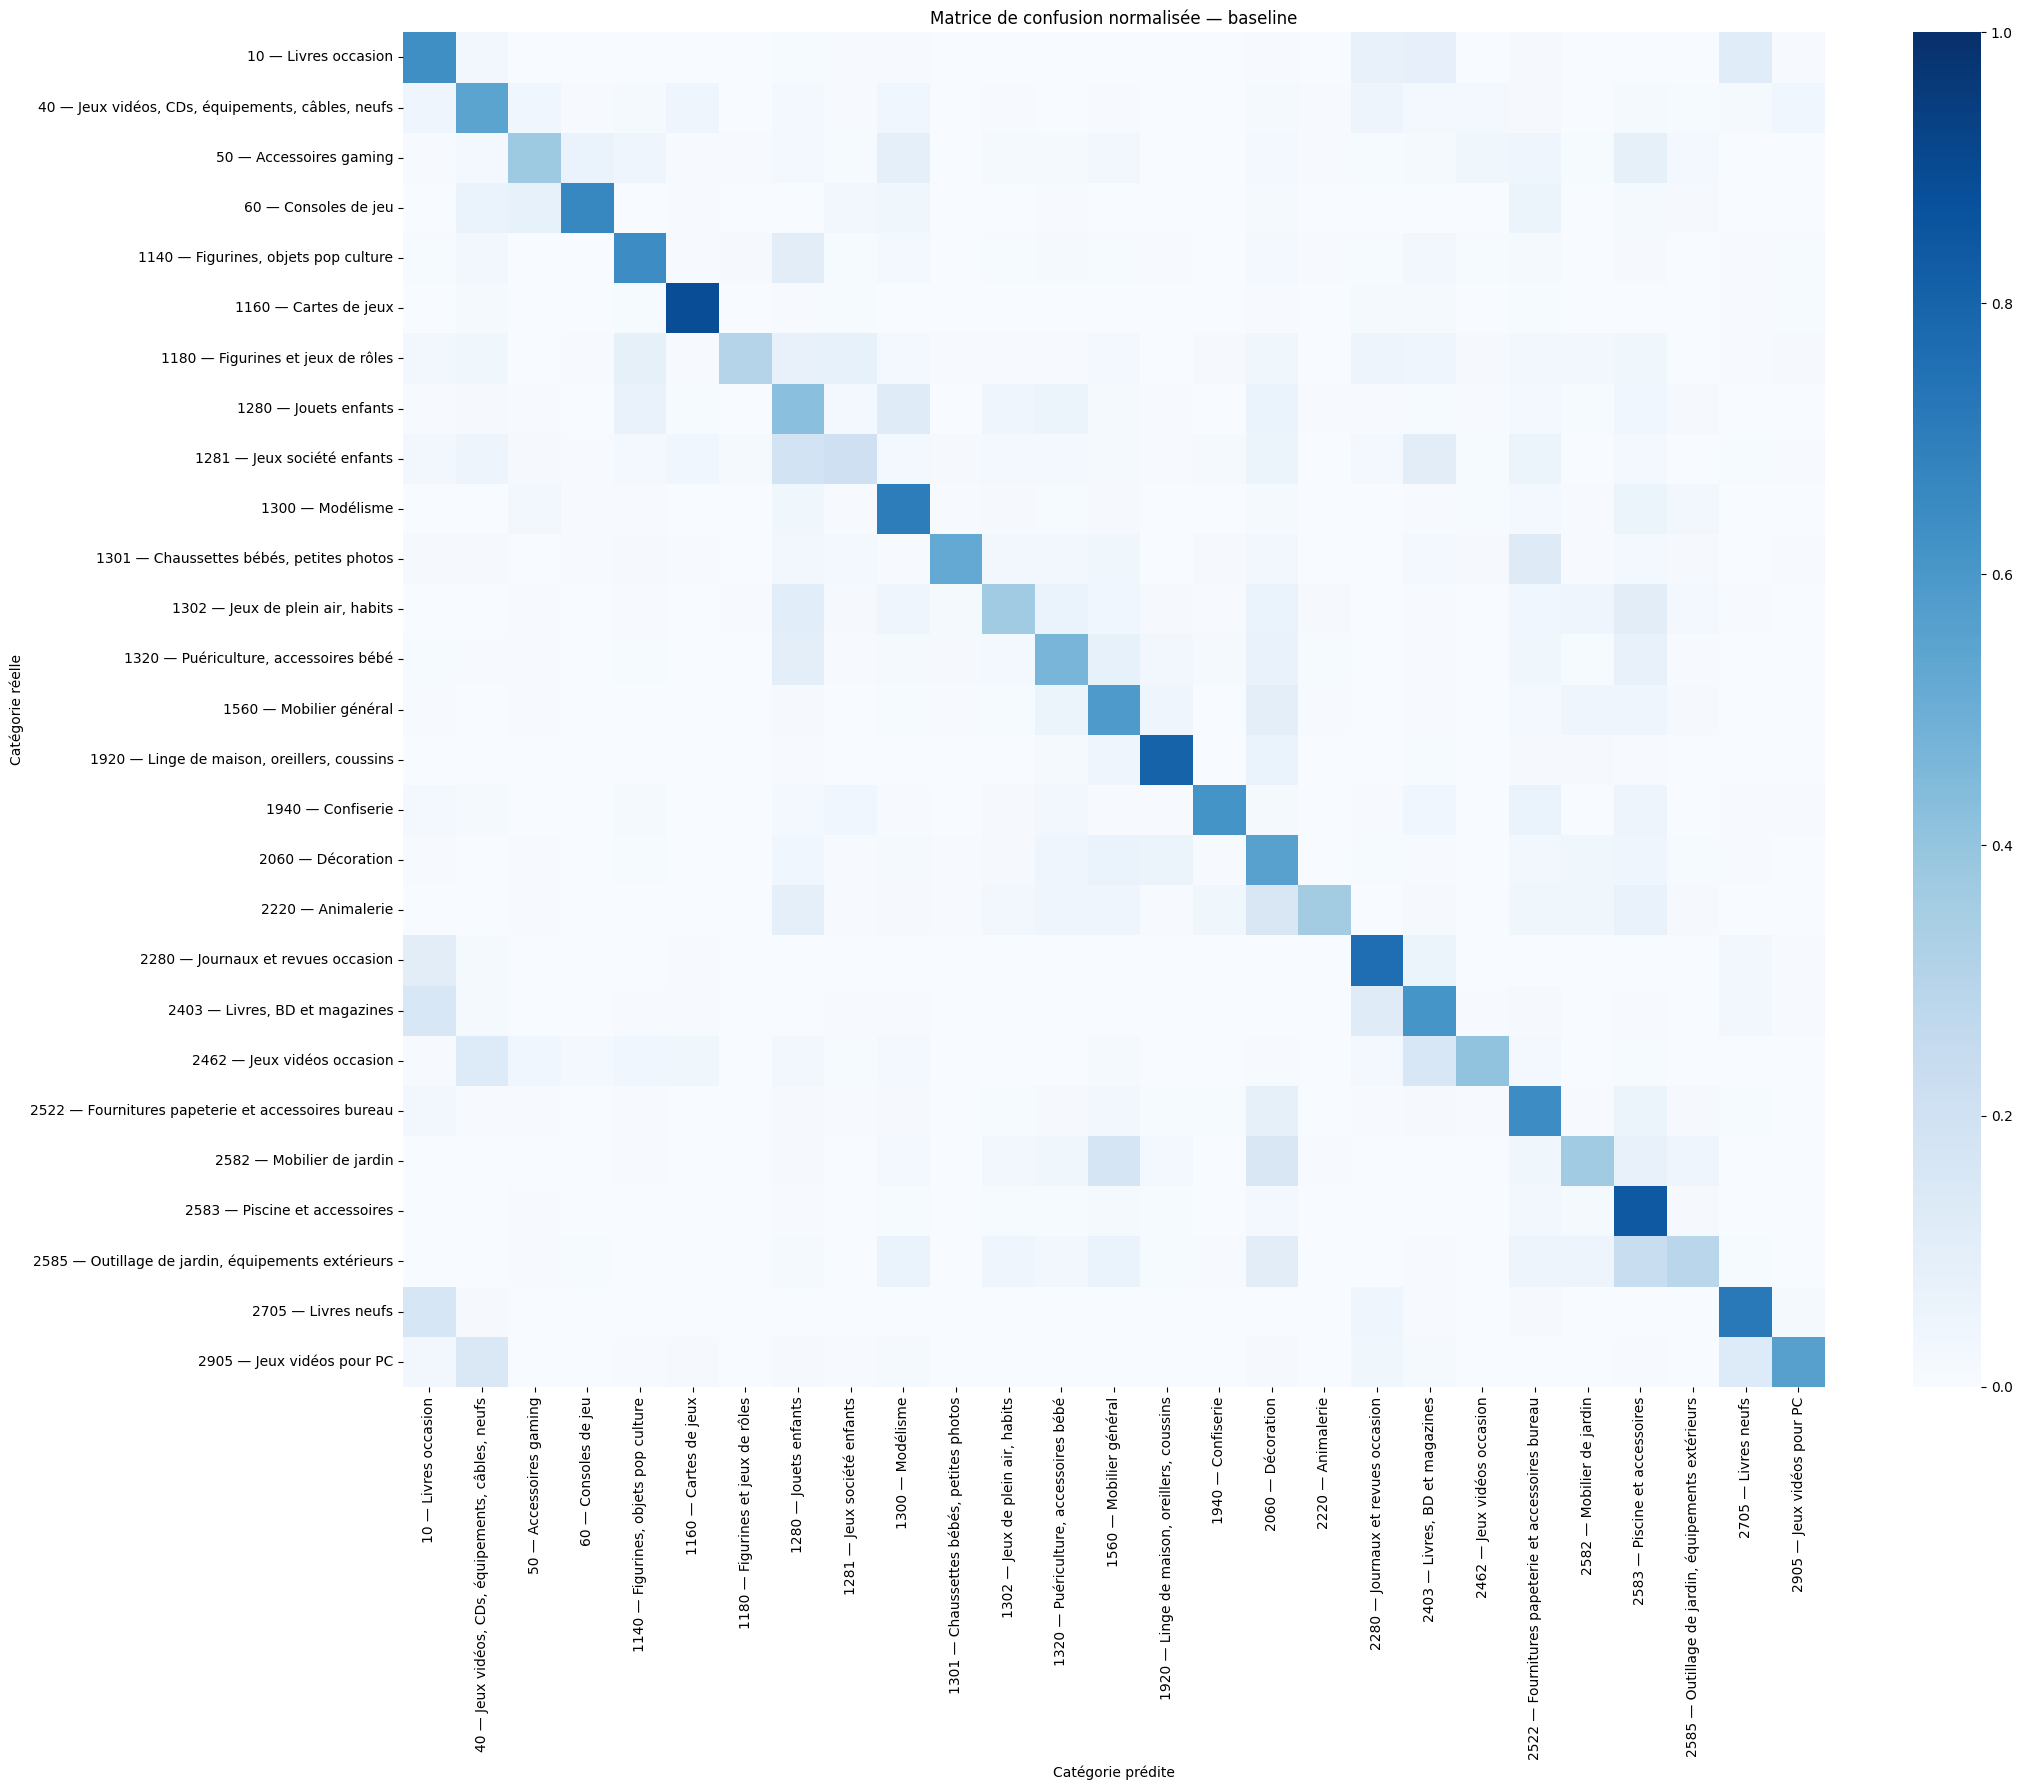

In [7]:
champion_pred = predictions[CHAMPION]["labels"]
matrix = confusion_matrix(y_true, champion_pred, normalize="true")
plt.figure(figsize=(22, 18))
sns.heatmap(
    matrix, cmap="Blues", vmin=0, vmax=1,
    xticklabels=readable_class_labels, yticklabels=readable_class_labels,
)
plt.title(f"Matrice de confusion normalisée — {CHAMPION}")
plt.xlabel("Catégorie prédite")
plt.ylabel("Catégorie réelle")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## 4. Examiner les erreurs les plus confiantes

    Ces exemples révèlent souvent des labels ambigus, des images non informatives ou des confusions métier
    récurrentes. Ils sont généralement plus utiles qu'une optimisation aveugle des hyperparamètres.


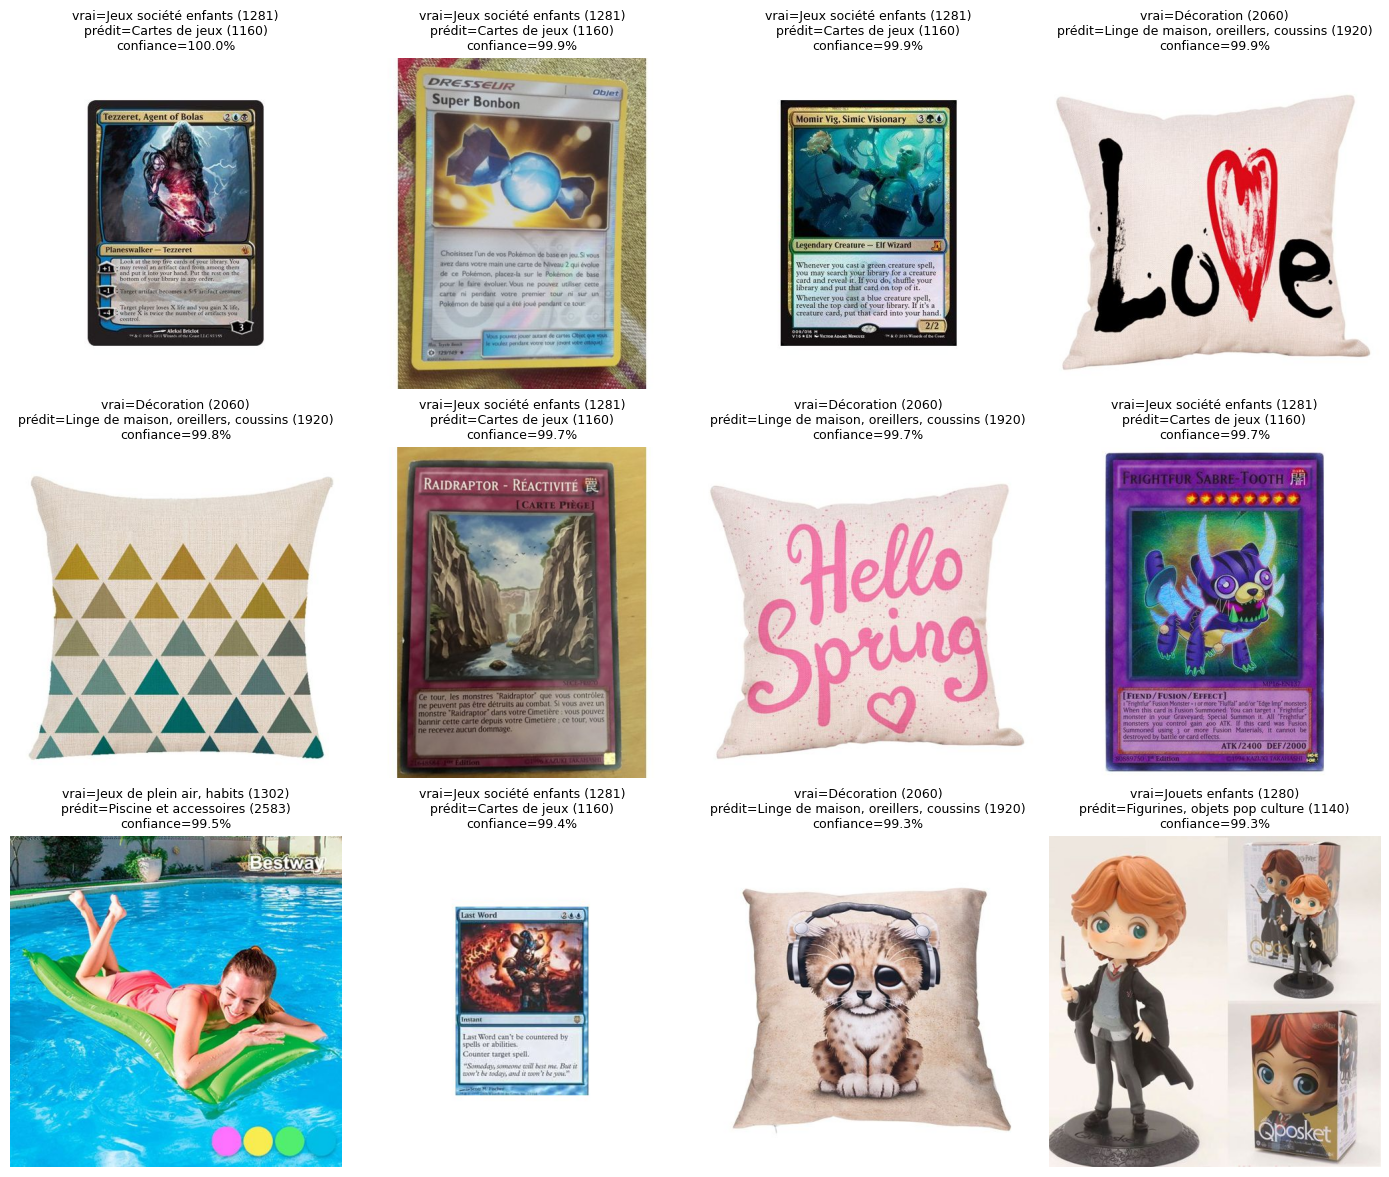

In [8]:
champion_proba = predictions[CHAMPION]["probabilities"]
errors = val_df.copy().reset_index(drop=True)
errors["true_index"] = y_true
errors["pred_index"] = champion_pred
errors["true_category"] = [category_names[index_to_code[index]] for index in y_true]
errors["pred_category"] = [category_names[index_to_code[index]] for index in champion_pred]
errors["confidence"] = champion_proba.max(axis=1)
errors = errors.query("true_index != pred_index").sort_values("confidence", ascending=False)

sample = errors.head(12)
fig, axes = plt.subplots(3, 4, figsize=(14, 12))
for ax, row in zip(axes.flat, sample.itertuples()):
    image = plt.imread(row.image_path)
    ax.imshow(image)
    ax.set_title(
        f"vrai={row.true_category} ({index_to_code[row.true_index]})\n"
        f"prédit={row.pred_category} ({index_to_code[row.pred_index]})\n"
        f"confiance={row.confidence:.1%}", fontsize=9,
    )
    ax.axis("off")
plt.tight_layout()
plt.show()


## 5. Prédire le jeu de test (optionnel)

    Cette section attend `data/raw_x_test.csv` avec les colonnes `Id`, `imageid` et `productid`. Elle produit
    `artifacts/image_classification/submission_image.csv` au format `Id,prdtypecode`, ainsi que
    `predictions_image_labeled.csv` avec le libellé métier associé.


In [9]:
TEST_CSV = DATA_DIR / "raw_x_test.csv"
if not TEST_CSV.exists():
    print("Étape ignorée : ajouter", TEST_CSV, "pour générer les prédictions de test.")
else:
    test = pd.read_csv(TEST_CSV)
    required = {"Id", "imageid", "productid"}
    assert required.issubset(test.columns), required - set(test.columns)
    test["image_path"] = test.apply(
        lambda row: str((ROOT / "images" / "image_test" /
            f"image_{row.imageid}_product_{row.productid}.jpg").resolve()), axis=1
    )
    assert test["image_path"].map(os.path.isfile).all()
    test["class_index"] = 0
    test["sample_weight"] = 1.0

    champion_run = experiments[CHAMPION]
    champion_model = load_evaluation_model(champion_run["path"])
    test_ds = make_dataset(test, transform=champion_run["transform"], weighted=False)
    test_probabilities = champion_model.predict(test_ds, verbose=1)
    test_codes = [index_to_code[index] for index in test_probabilities.argmax(axis=1)]
    submission = pd.DataFrame({"Id": test["Id"], "prdtypecode": test_codes})
    submission.to_csv(ARTIFACTS_DIR / "submission_image.csv", index=False)

    labeled_predictions = submission.copy()
    labeled_predictions["category_name"] = labeled_predictions["prdtypecode"].map(category_names)
    labeled_predictions.to_csv(
        ARTIFACTS_DIR / "predictions_image_labeled.csv", index=False
    )
    display(labeled_predictions.head())


Étape ignorée : ajouter /Users/wolfidy7/projects/sep25_alt2_iia_rakuten_2/data/raw_x_test.csv pour générer les prédictions de test.
